# Point-in-Time Residual Returns

Computing beta-adjusted residual returns in a point-in-time way suitable for backtesting (no lookahead).

- Universe: FB, AAPL, AMZN, NFLX, GOOGL, with QQQ as the tech benchmark.
- Estimate each stock's beta to QQQ over a rolling lookback window.
- Strip out the beta component to recover residual (idiosyncratic) returns for each stock.

_Uses the repo's `yahoo.py` downloader. Problem prompts paraphrased; all code is my own._

In [55]:
import importlib
import yahoo as yf
import pandas as pd
import numpy as np
importlib.reload(yf)
import statsmodels.api as sm

In [12]:
univ = ['META', 'AAPL', 'AMZN', 'NFLX', 'GOOGL', 'QQQ']
px = yf.download(univ, start="2016-01-01")['Adj Close']

In [13]:
px

,META,AAPL,AMZN,NFLX,GOOGL,QQQ
Date,,,,,,
2016-01-04,101.330170,23.688677,31.849501,10.996000,37.638256,101.605621
2016-01-05,101.835724,23.095055,31.689501,10.766000,37.741833,101.429321
2016-01-06,102.073639,22.643089,31.632500,11.768000,37.632801,100.455009
2016-01-07,97.067596,21.687447,30.396999,11.456000,36.724358,97.309441
2016-01-08,96.482735,21.802124,30.352501,11.139000,36.224289,96.511421
...,...,...,...,...,...,...
2026-08-14,589.849976,305.929993,262.649994,78.160004,345.899994,731.070007
2026-08-17,568.969971,305.589996,261.309998,76.019997,344.000000,729.869995
2026-08-18,543.669983,310.029999,259.450012,77.769997,344.200012,717.510010


In [28]:
ret = px / px.shift() - 1
ret = ret.dropna()
ret

,META,AAPL,AMZN,NFLX,GOOGL,QQQ
Date,,,,,,
2016-01-05,0.004989,-0.025059,-0.005024,-0.020917,0.002752,-0.001735
2016-01-06,0.002336,-0.019570,-0.001799,0.093071,-0.002889,-0.009606
2016-01-07,-0.049043,-0.042205,-0.039058,-0.026513,-0.024140,-0.031313
2016-01-08,-0.006025,0.005288,-0.001464,-0.027671,-0.013617,-0.008201
2016-01-11,0.001849,0.016192,0.017610,0.032139,0.002955,0.003077
...,...,...,...,...,...,...
2026-08-14,-0.008605,0.002195,-0.009354,-0.001022,-0.001328,-0.001366
2026-08-17,-0.035399,-0.001111,-0.005102,-0.027380,-0.005493,-0.001641
2026-08-18,-0.044466,0.014529,-0.007118,0.023020,0.000581,-0.016935


In [34]:
QQQ = ret['QQQ']
QQQ = sm.add_constant(QQQ)

META = ret['META']
AAPL = ret['AAPL']
AMZN = ret['AMZN']
NFLX = ret['NFLX']
GOOGL = ret['GOOGL']

R_META = sm.OLS(META, QQQ).fit()
R_AAPL = sm.OLS(AAPL, QQQ).fit()
R_AMZN = sm.OLS(AMZN, QQQ).fit()
R_NFLX = sm.OLS(NFLX, QQQ).fit()
R_GOOGL = sm.OLS(GOOGL, QQQ).fit()

S_META = R_META.params['QQQ'] * QQQ['QQQ'] + R_META.params['const'] + R_META.resid
S_AAPL = R_AAPL.params['QQQ'] * QQQ['QQQ'] + R_AAPL.params['const'] + R_AAPL.resid
S_AMZN = R_AMZN.params['QQQ'] * QQQ['QQQ'] + R_AMZN.params['const'] + R_AMZN.resid
S_NFLX = R_NFLX.params['QQQ'] * QQQ['QQQ'] + R_NFLX.params['const'] + R_NFLX.resid
S_GOOGL = R_GOOGL.params['QQQ'] * QQQ['QQQ'] + R_GOOGL.params['const'] + R_GOOGL.resid

Date
2016-01-05    0.004989
2016-01-06    0.002336
2016-01-07   -0.049043
2016-01-08   -0.006025
2016-01-11    0.001849
                ...   
2026-08-14   -0.008605
2026-08-17   -0.035399
2026-08-18   -0.044466
2026-08-19    0.004341
2026-08-20   -0.004725
Length: 2672, dtype: float64

In [62]:
# Beta Contribution

B_META = R_META.params['QQQ'] * QQQ['QQQ']
B_AAPL = R_AAPL.params['QQQ'] * QQQ['QQQ']
B_AMZN = R_AMZN.params['QQQ'] * QQQ['QQQ']
B_NFLX = R_NFLX.params['QQQ'] * QQQ['QQQ']
B_GOOGL = R_GOOGL.params['QQQ'] * QQQ['QQQ']

print(B_GOOGL)

Date
2016-01-05   -0.001732
2016-01-06   -0.009588
2016-01-07   -0.031254
2016-01-08   -0.008185
2016-01-11    0.003071
                ...   
2026-08-14   -0.001363
2026-08-17   -0.001638
2026-08-18   -0.016903
2026-08-19   -0.001989
2026-08-20   -0.006384
Name: QQQ, Length: 2672, dtype: float64


In [40]:
# Alpha Contribution

A_META = R_META.params['const'] + R_META.resid
A_AAPL = R_AAPL.params['const'] + R_AAPL.resid
A_AMZN = R_AMZN.params['const'] + R_AMZN.resid
A_NFLX = R_NFLX.params['const'] + R_NFLX.resid
A_GOOGL = R_GOOGL.params['const'] + R_GOOGL.resid

<Axes: xlabel='Date'>

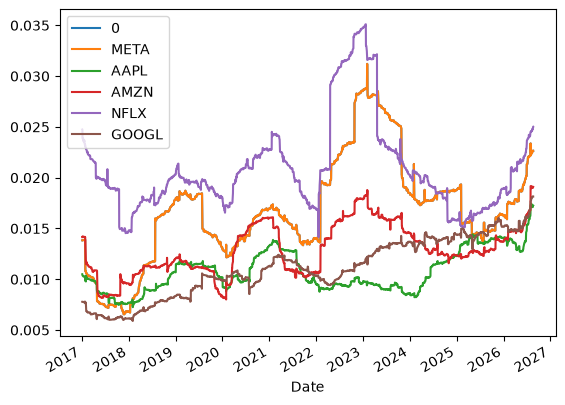

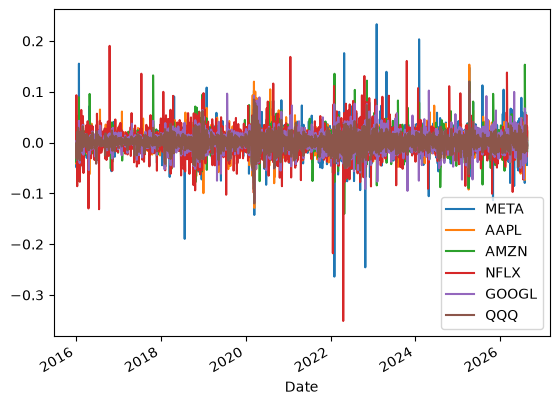

In [52]:
# Volatility

V_META = A_META.rolling(252).std()
V_AAPL = A_AAPL.rolling(252).std()
V_AMZN = A_AMZN.rolling(252).std()
V_NFLX = A_NFLX.rolling(252).std()
V_GOOGL = A_GOOGL.rolling(252).std()


V['META'] = pd.DataFrame(V_META)
V['AAPL'] = pd.DataFrame(V_AAPL)
V['AMZN'] = pd.DataFrame(V_AMZN)
V['NFLX'] = pd.DataFrame(V_NFLX)
V['GOOGL'] = pd.DataFrame(V_GOOGL)

V.plot()
ret.plot()

In [54]:
# Correlation to QQQ
C_META = A_META.corr(QQQ['QQQ'])
C_AAPL = A_AAPL.corr(QQQ['QQQ'])
C_AMZN = A_AMZN.corr(QQQ['QQQ'])
C_NFLX = A_NFLX.corr(QQQ['QQQ'])
C_GOOGL = A_GOOGL.corr(QQQ['QQQ'])

In [57]:
# Information Ratio

IR_META = A_META.mean() / A_META.std() * np.sqrt(252)
IR_AAPL = A_AAPL.mean() / A_AAPL.std() * np.sqrt(252)
IR_AMZN = A_AMZN.mean() / A_AMZN.std() * np.sqrt(252)
IR_NFLX = A_NFLX.mean() / A_NFLX.std() * np.sqrt(252)
IR_GOOGL = A_GOOGL.mean() / A_GOOGL.std() * np.sqrt(252)

In [58]:
# Sharpe Ratio

SR_META = ret['META'].mean() / ret['META'].std() * np.sqrt(252)
SR_AAPL = ret['AAPL'].mean() / ret['AAPL'].std() * np.sqrt(252)
SR_AMZN = ret['AMZN'].mean() / ret['AMZN'].std() * np.sqrt(252)
SR_NFLX = ret['NFLX'].mean() / ret['NFLX'].std() * np.sqrt(252)
SR_GOOGL = ret['GOOGL'].mean() / ret['GOOGL'].std() * np.sqrt(252)

In [63]:
print(IR_NFLX)
print(SR_NFLX)

0.171338846598473
0.6631147437409981
